In [4]:
import librosa
import librosa.display
import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np

In [5]:
mahabharat_title_electric=r"C:\Users\hgp99\OneDrive\Desktop\Electric Guitar\mahabharat title track.mp3"
rachmaninoff=r"C:\Users\hgp99\Downloads\ytmp3free.cc_rachmaninoff-piano-concerto-2-best-part-youtubemp3free.org.mp3"


In [6]:
ipd.Audio(mahabharat_title_electric)

In [7]:
ipd.Audio(rachmaninoff)

In [8]:
mahabharat,sr1 = librosa.load(mahabharat_title_electric)
rach,sr2=librosa.load(rachmaninoff)

In [9]:
mahabharat

array([ 0.000000e+00,  0.000000e+00,  0.000000e+00, ...,  9.680668e-06,
       -5.508865e-06,  0.000000e+00], dtype=float32)

In [10]:
mahabharat.size

3460270

In [11]:
# duration of one sample
sample_duration=1/sr1
print(f"duration of one sample is {sample_duration :.6f} seconds")

duration of one sample is 0.000045 seconds


In [12]:
duration= sample_duration*len(mahabharat)
print(f"duration of signal is {duration:.2f} seconds")

duration of signal is 156.93 seconds


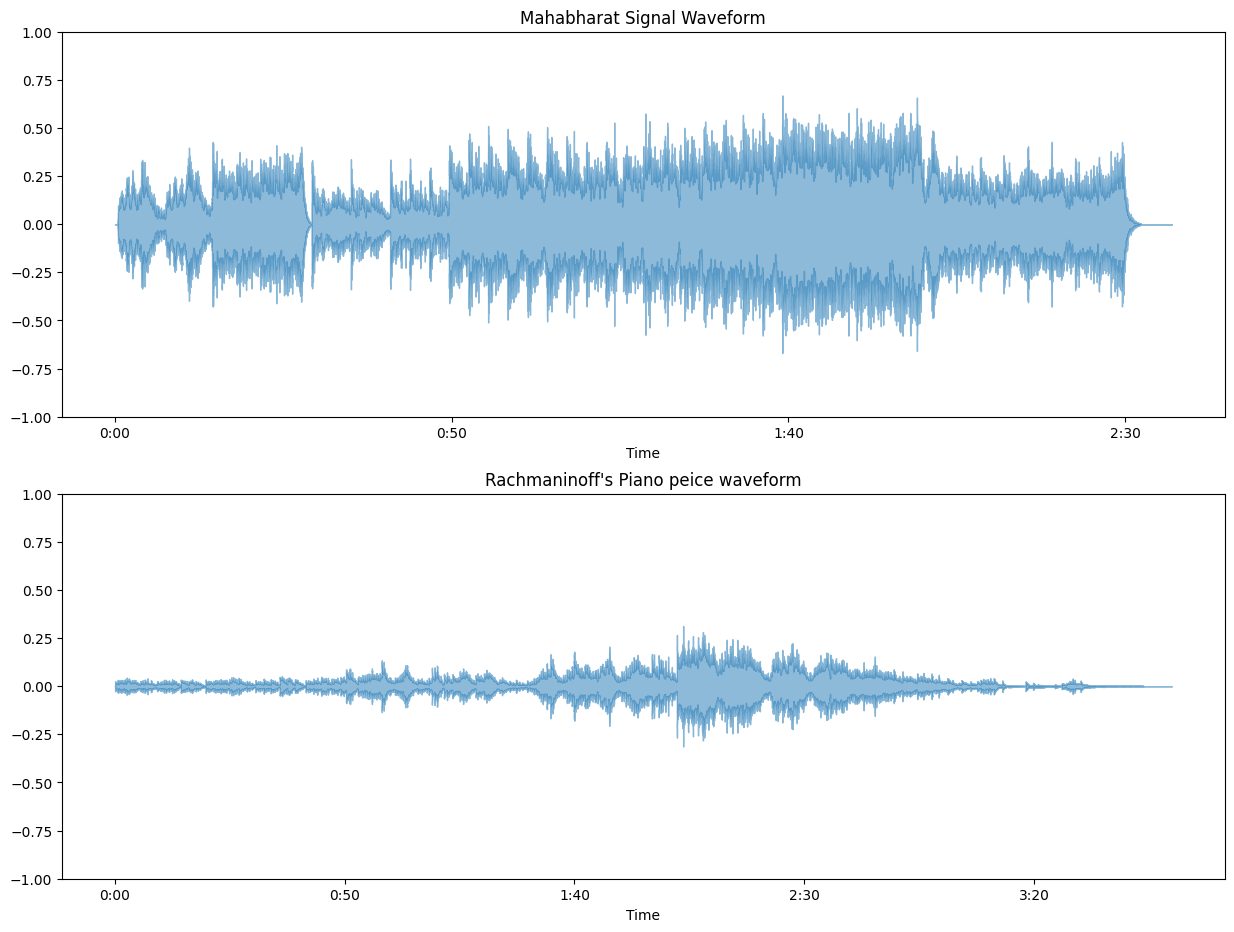

In [13]:
plt.figure(figsize=(15, 17))
plt.subplot(3, 1, 1)
librosa.display.waveshow(mahabharat, sr=sr1,alpha=0.5)
plt.title("Mahabharat Signal Waveform")
plt.ylim((-1, 1))
plt.subplot(3, 1, 2)
librosa.display.waveshow(rach, sr=sr2,alpha=0.5)
plt.title("Rachmaninoff's Piano peice waveform")
plt.ylim((-1, 1))
plt.show()

In [22]:
#calulate the amplitude envelope
FRAME_SIZE= 1024
HOP_LENGTH= 512
def amplitude_envelope(signal,frame_size,hop_length):
    amplitude_envelope= []

    #calculate AE for each frame
    for i in range(0,len(signal),hop_length):
        current_frame_amplitude_envelope= max(signal[i:i+frame_size])
        amplitude_envelope.append(current_frame_amplitude_envelope)
    return np.array(amplitude_envelope)

def fancy_amplitude_envelope(signal,frame_size,hop_length):
    return np.array([max(signal[i:i+frame_size]) for i in range(0, signal.size, hop_length)])

In [26]:
ae_mahabharat= amplitude_envelope(mahabharat,FRAME_SIZE,HOP_LENGTH)
ae_rach=amplitude_envelope(rachmaninoff,FRAME_SIZE,HOP_LENGTH)
len(ae_mahabharat)

6759

In [27]:
fancy_ae_mahabharat=fancy_amplitude_envelope(mahabharat,FRAME_SIZE,HOP_LENGTH)
(ae_mahabharat==fancy_ae_mahabharat).all()

True

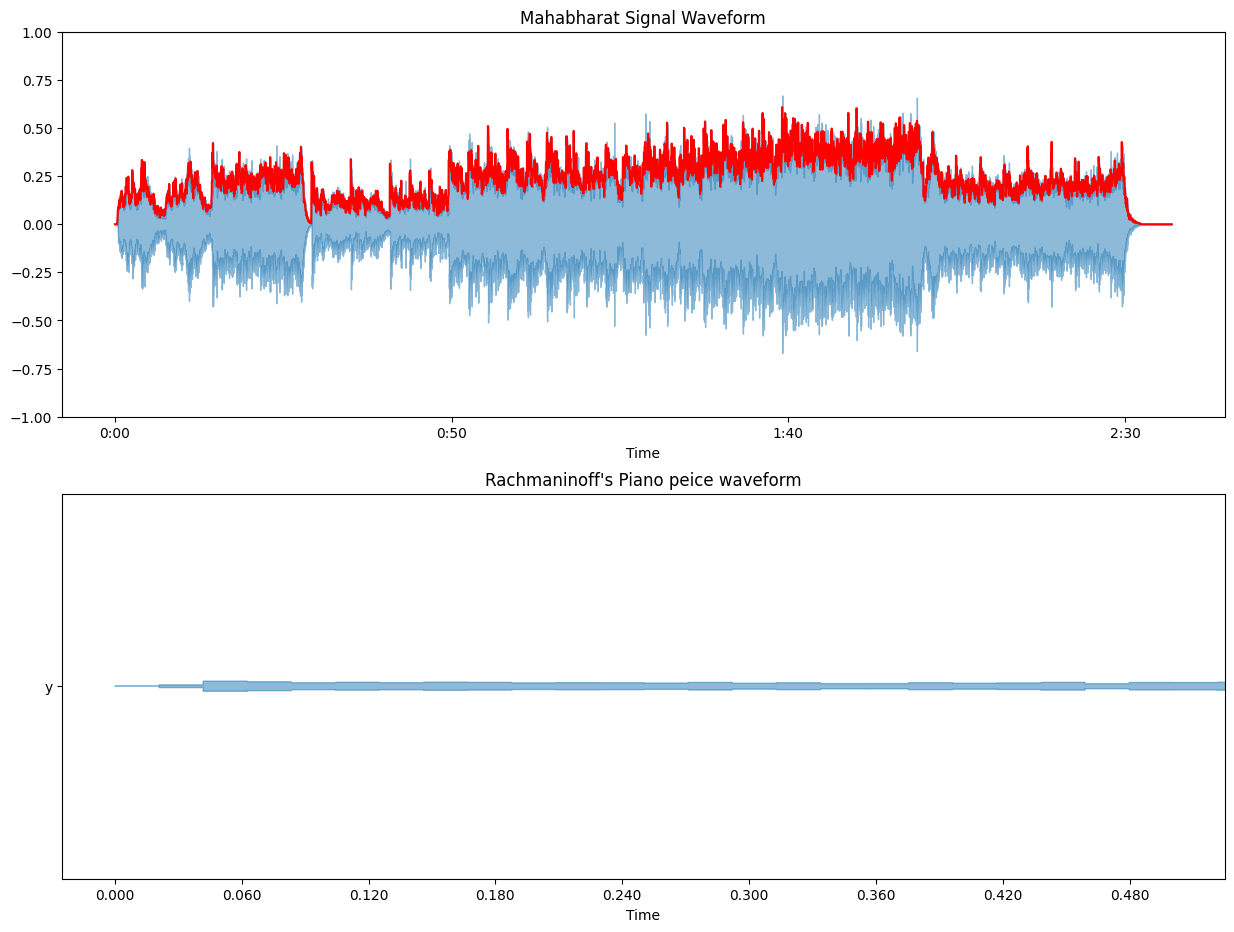

In [37]:
frames=range(0,ae_mahabharat.size)
t=librosa.frames_to_time(frames,hop_length=HOP_LENGTH)

frame_r=range(0,ae_rach.size)
t_r=librosa.frames_to_time(frames_r,hop_length=HOP_LENGTH)

plt.figure(figsize=(15, 17))
plt.subplot(3, 1, 1)
librosa.display.waveshow(mahabharat, sr=sr1,alpha=0.5)
plt.plot(t,ae_mahabharat,color='r')
plt.title("Mahabharat Signal Waveform")
plt.ylim((-1, 1))
plt.subplot(3, 1, 2)
librosa.display.waveshow(rach, sr=sr2,alpha=0.5)
plt.plot(t_r,ae_rach,color='r')
plt.title("Rachmaninoff's Piano peice waveform")
plt.ylim((-1, 1))
plt.show()